# Import the packages

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Load the Big dataset (df1)

1) HANDLING MISSING DATA

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display

# Dataset 1 (Survey / Big)
df1 = pd.read_csv('/content/drive/MyDrive/datasets/diabetes_big.csv')
print("Dataset 1 Head:")
display(df1.head())
print("Dataset 1 Info:")
print(df1.info())



Dataset 1 Head:


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


Dataset 1 Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  float64
 14  GenHlth               70692 non-null  float64
 15  Men

2) HANDLING OUTLIERS

In [ ]:
import pandas as pd

# Load the dataset
df1 = pd.read_csv('/content/drive/MyDrive/datasets/diabetes_big.csv')

# --- 1. Inspect Before Handling ---
print("--- BMI Statistics Before Capping ---")
print(df1['BMI'].describe())

# --- 2. Define Capping Threshold ---
# We use the 99th percentile to cap extreme outliers
upper_limit = df1['BMI'].quantile(0.99)
print(f"\nCapping Threshold (99th percentile): {upper_limit}")

# Identify how many rows will be affected
outliers_count = (df1['BMI'] > upper_limit).sum()
print(f"Number of rows to be capped: {outliers_count}")

# Replace values greater than the threshold with the threshold value
df1.loc[df1['BMI'] > upper_limit, 'BMI'] = upper_limit

# --- 4. Inspect After Handling ---
print("\n--- BMI Statistics After Capping ---")
print(df1['BMI'].describe())

--- BMI Statistics Before Capping ---
count    70692.000000
mean        29.856985
std          7.113954
min         12.000000
25%         25.000000
50%         29.000000
75%         33.000000
max         98.000000
Name: BMI, dtype: float64

Capping Threshold (99th percentile): 52.0
Number of rows to be capped: 690

--- BMI Statistics After Capping ---
count    70692.000000
mean        29.756125
std          6.629855
min         12.000000
25%         25.000000
50%         29.000000
75%         33.000000
max         52.000000
Name: BMI, dtype: float64


3. Modify clean_df1

In [ ]:
def clean_df1_survey(df):
    """Cleaning logic for Dataset 1"""
    df = df.copy()

    # Map Age Categories
    age_map = {1:21, 2:27, 3:32, 4:37, 5:42, 6:47, 7:52, 8:57, 9:62, 10:67, 11:72, 12:77, 13:82}
    df['Age_Raw'] = df['Age'].map(age_map)

    # Return standard columns
    return df[['Diabetes_binary', 'HighBP', 'BMI', 'Sex', 'Age_Raw']]

In [ ]:
print(df1.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  float64
 14  GenHlth               70692 non-null  float64
 15  MentHlth           

# Load the Small dataset (df2)

1) HANDLING MISSING DATA

In [ ]:
# Dataset 2 (Pima / Small)
df2 = pd.read_csv('/content/drive/MyDrive/datasets/pima_small.csv')
print("\nDataset 2 Head:")
display(df2.head())
print("Dataset 2 Info:")
print(df2.info())


Dataset 2 Head:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Dataset 2 Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [ ]:
print("\nNumber of 0s in key columns before handling:")
for col in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    print(f"{col}: {(df2[col] == 0).sum()}")


Number of 0s in key columns before handling:
Glucose: 5
BloodPressure: 35
SkinThickness: 227
Insulin: 374
BMI: 11


After Missing Value Handling

In [ ]:
cols_to_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# --- Step 1: Replace 0 with NaN ---
df2[cols_to_fix] = df2[cols_to_fix].replace(0, np.nan)

# --- Step 2: Fill NaN with Median ---
for col in cols_to_fix:
    median_val = df2[col].median()
    df2[col] = df2[col].fillna(median_val)

print("\nNumber of 0s in key columns after handling:")
for col in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    print(f"{col}: {(df2[col] == 0).sum()}")


Number of 0s in key columns after handling:
Glucose: 0
BloodPressure: 0
SkinThickness: 0
Insulin: 0
BMI: 0


3. Modify clean_df2



In [ ]:
def clean_df3_pima(df):
    """Cleaning logic for Dataset 3"""
    df = df.copy()

    # Create Target & HighBP
    df['Diabetes_binary'] = df['Outcome']
    df['HighBP'] = np.where(df['BloodPressure'] > 80, 1, 0)

    # Create Sex (Assign 0 or 1 randomly 50/50)
    df['Sex'] = np.random.randint(0, 2, size=len(df))

    # Rename columns
    df['Age_Raw'] = df['Age']
    # BMI is already named BMI

    return df[['Diabetes_binary', 'HighBP', 'BMI', 'Sex', 'Age_Raw']]

### **Feature Engineering Function Definition**

In [ ]:
def feature_engineering(df):
    """Applies math transformations to standard columns."""
    df = df.copy()

    # 1. Normalize Age
    df['Age_Normalized'] = df['Age_Raw'] / 100.0

    # 2. Metabolic Score
    df['Metabolic_Score'] = df['BMI'] * (df['HighBP'] + 1)

    # 3. Age Weighted BMI
    df['Age_Weighted_BMI'] = df['BMI'] * df['Age_Normalized']

    # 4. HighBP Impact
    df['Age_HighBP'] = df['Age_Normalized'] * df['HighBP']

    # Drop intermediate column
    return df.drop(columns=['Age_Raw'])

### **Applying Cleaning and Feature Engineering to DataFrames**

In [ ]:
# Assuming df1 and df2 are already loaded and pre-processed (e.g., missing values handled)
# If you haven't loaded them, please ensure you run the cells that load df1 and df2.

# Apply cleaning functions
df1_cleaned = clean_df1_survey(df1)
df2_cleaned = clean_df3_pima(df2)

# Apply feature engineering
df1_final = feature_engineering(df1_cleaned)
df2_final = feature_engineering(df2_cleaned)

# Display Results
print("\n### Dataset 1 Final (Cleaned and Engineered) ###")
display(df1_final.head())

print("\n### Dataset 2 Final (Cleaned and Engineered) ###")
display(df2_final.head())


### Dataset 1 Final (Cleaned and Engineered) ###


,Diabetes_binary,HighBP,BMI,Sex,Age_Normalized,Metabolic_Score,Age_Weighted_BMI,Age_HighBP
0,0.0,1.0,26.0,1.0,0.37,52.0,9.62,0.37
1,0.0,1.0,26.0,1.0,0.77,52.0,20.02,0.77
2,0.0,0.0,26.0,1.0,0.82,26.0,21.32,0.00
3,0.0,1.0,28.0,1.0,0.72,56.0,20.16,0.72
4,0.0,0.0,29.0,0.0,0.57,29.0,16.53,0.00



### Dataset 2 Final (Cleaned and Engineered) ###


,Diabetes_binary,HighBP,BMI,Sex,Age_Normalized,Metabolic_Score,Age_Weighted_BMI,Age_HighBP
0,1,0,33.6,1,0.50,33.6,16.800,0.0
1,0,0,26.6,1,0.31,26.6,8.246,0.0
2,1,0,23.3,1,0.32,23.3,7.456,0.0
3,0,0,28.1,1,0.21,28.1,5.901,0.0
4,1,0,43.1,1,0.33,43.1,14.223,0.0


## Visualize Core Features for Dataset 1



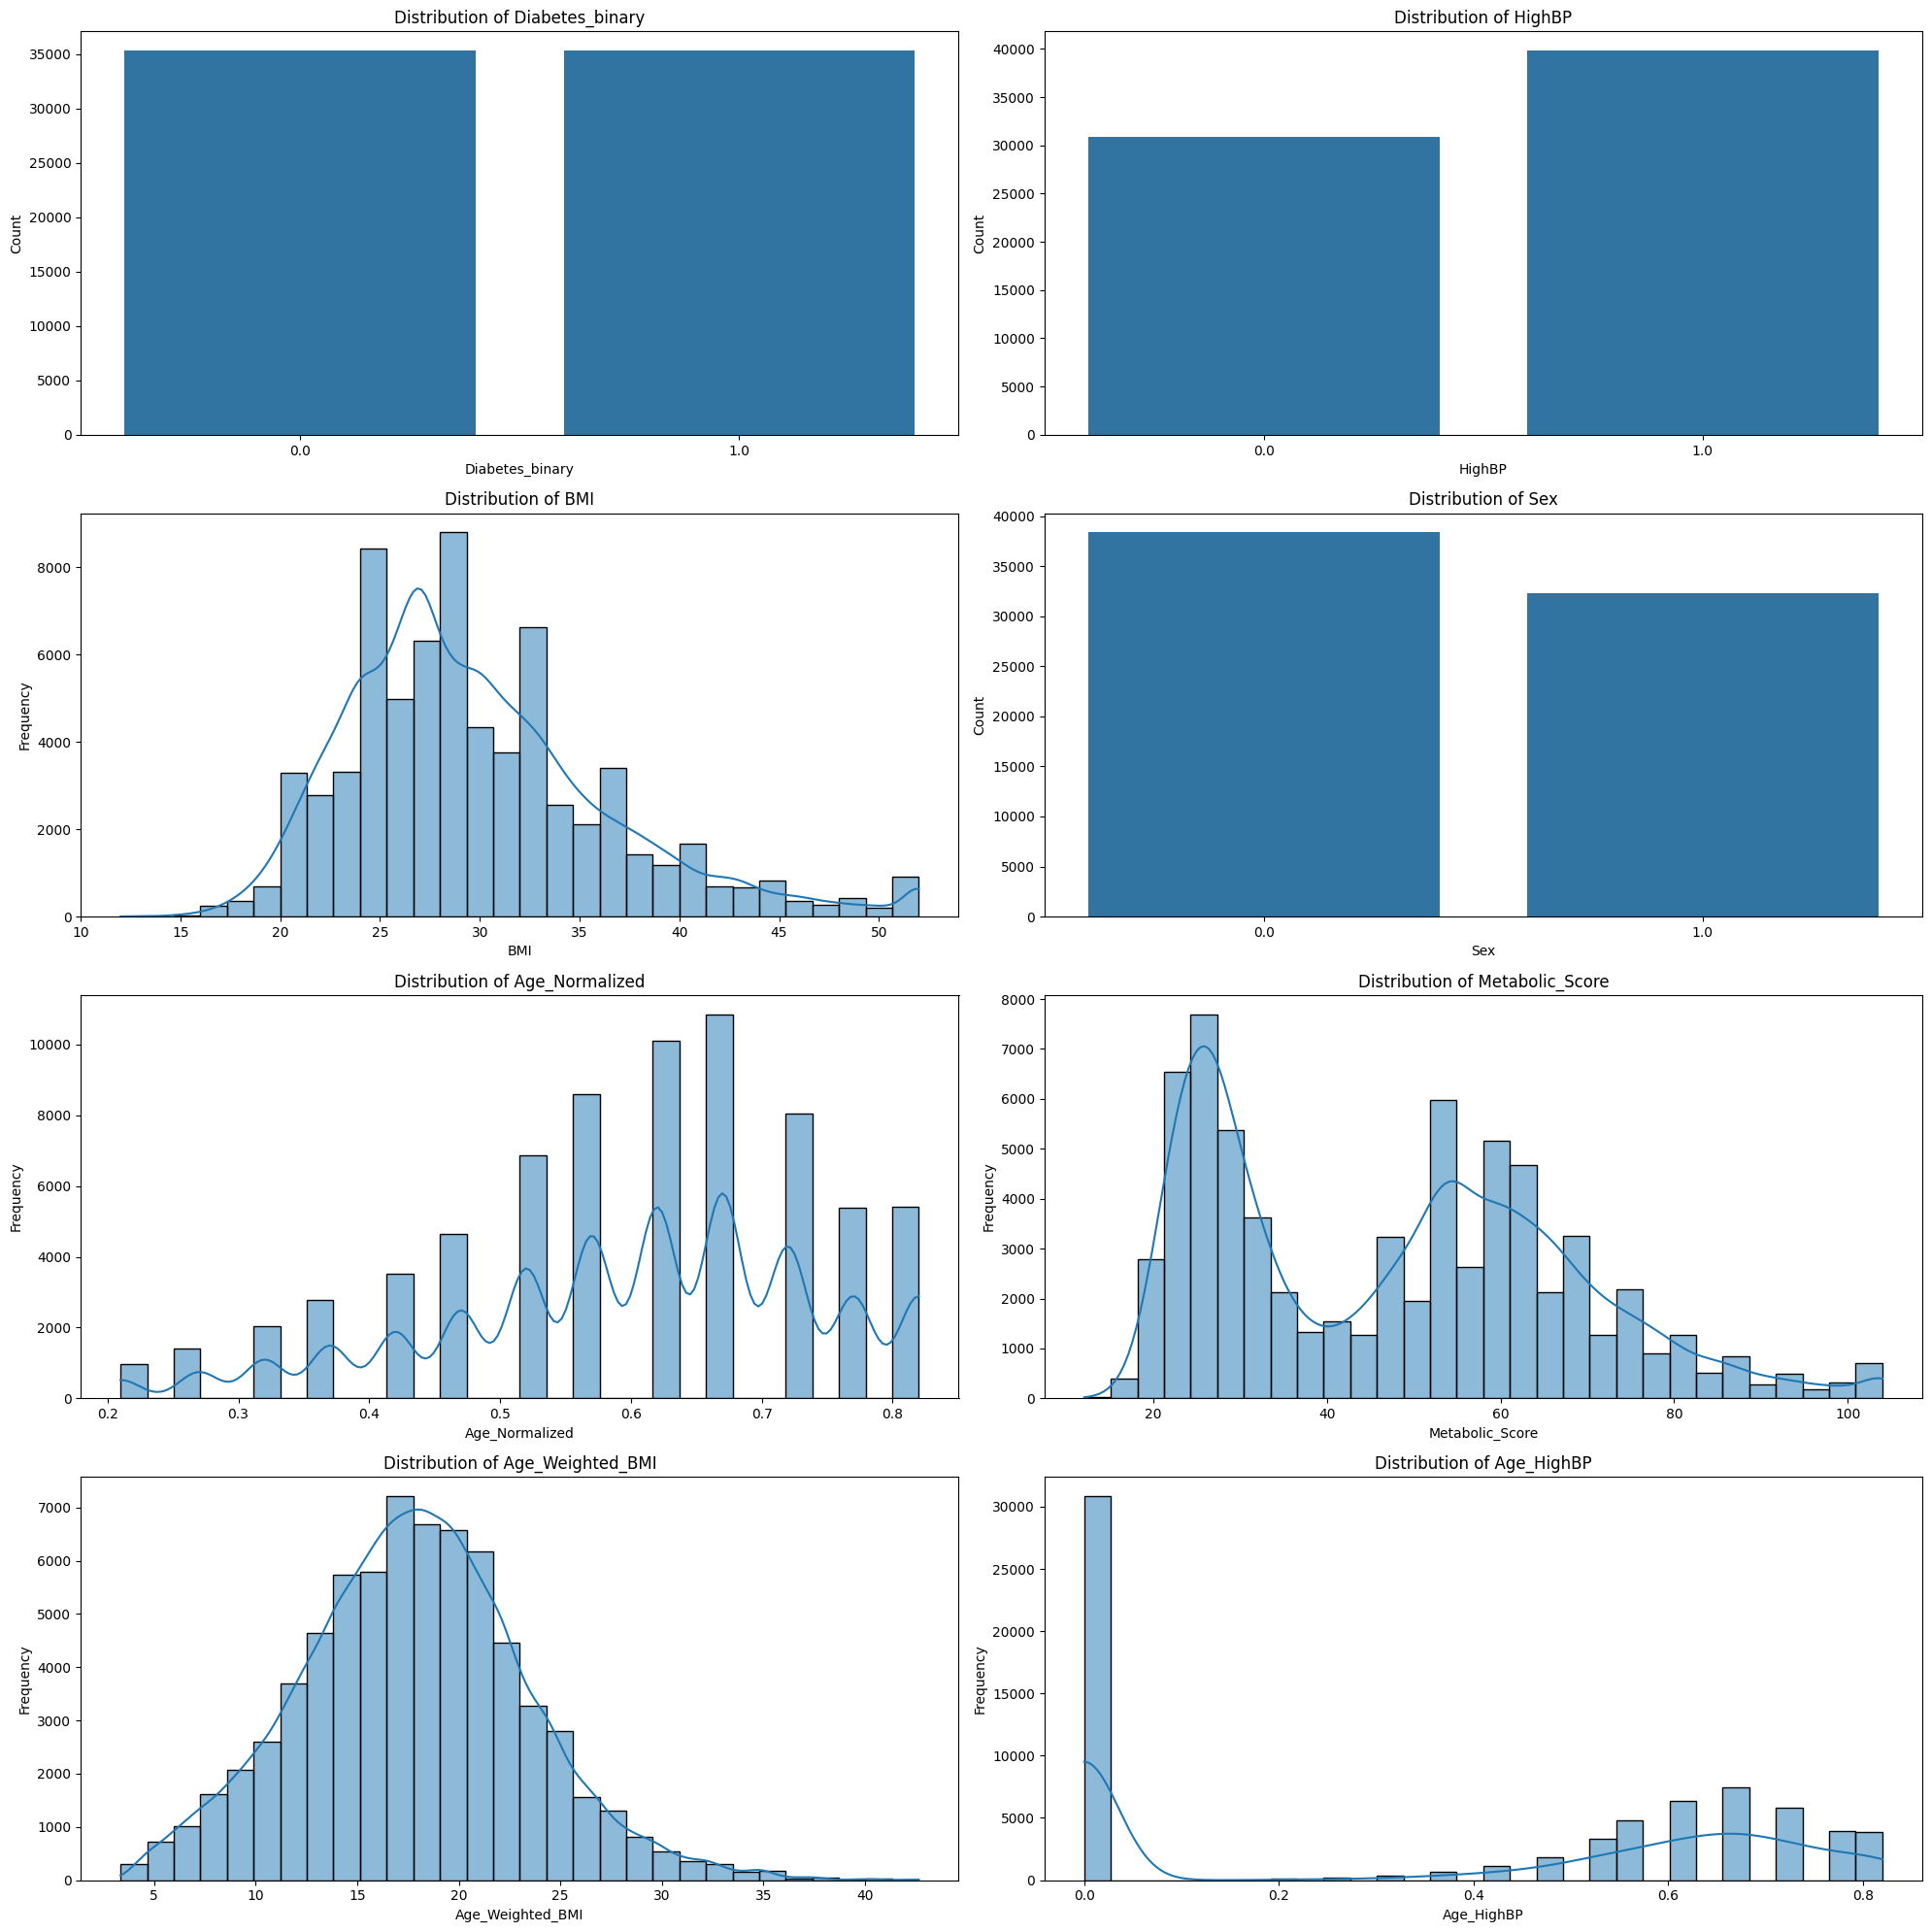

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(20, 20))
axes = axes.flatten() # Flatten the 4x2 array of axes for easy iteration

features_to_visualize = [
    'Diabetes_binary', 'HighBP', 'BMI', 'Sex', 'Age_Normalized',
    'Metabolic_Score', 'Age_Weighted_BMI', 'Age_HighBP'
]

for i, feature in enumerate(features_to_visualize):
    ax = axes[i]
    if feature in ['Diabetes_binary', 'HighBP', 'Sex']:
        sns.countplot(x=feature, data=df1_final, ax=ax)
        ax.set_ylabel('Count')
    else:
        sns.histplot(df1_final[feature], bins=30, kde=True, ax=ax)
        ax.set_ylabel('Frequency')

    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)

plt.tight_layout()
plt.show()

## Visualize Core Features for Dataset 2



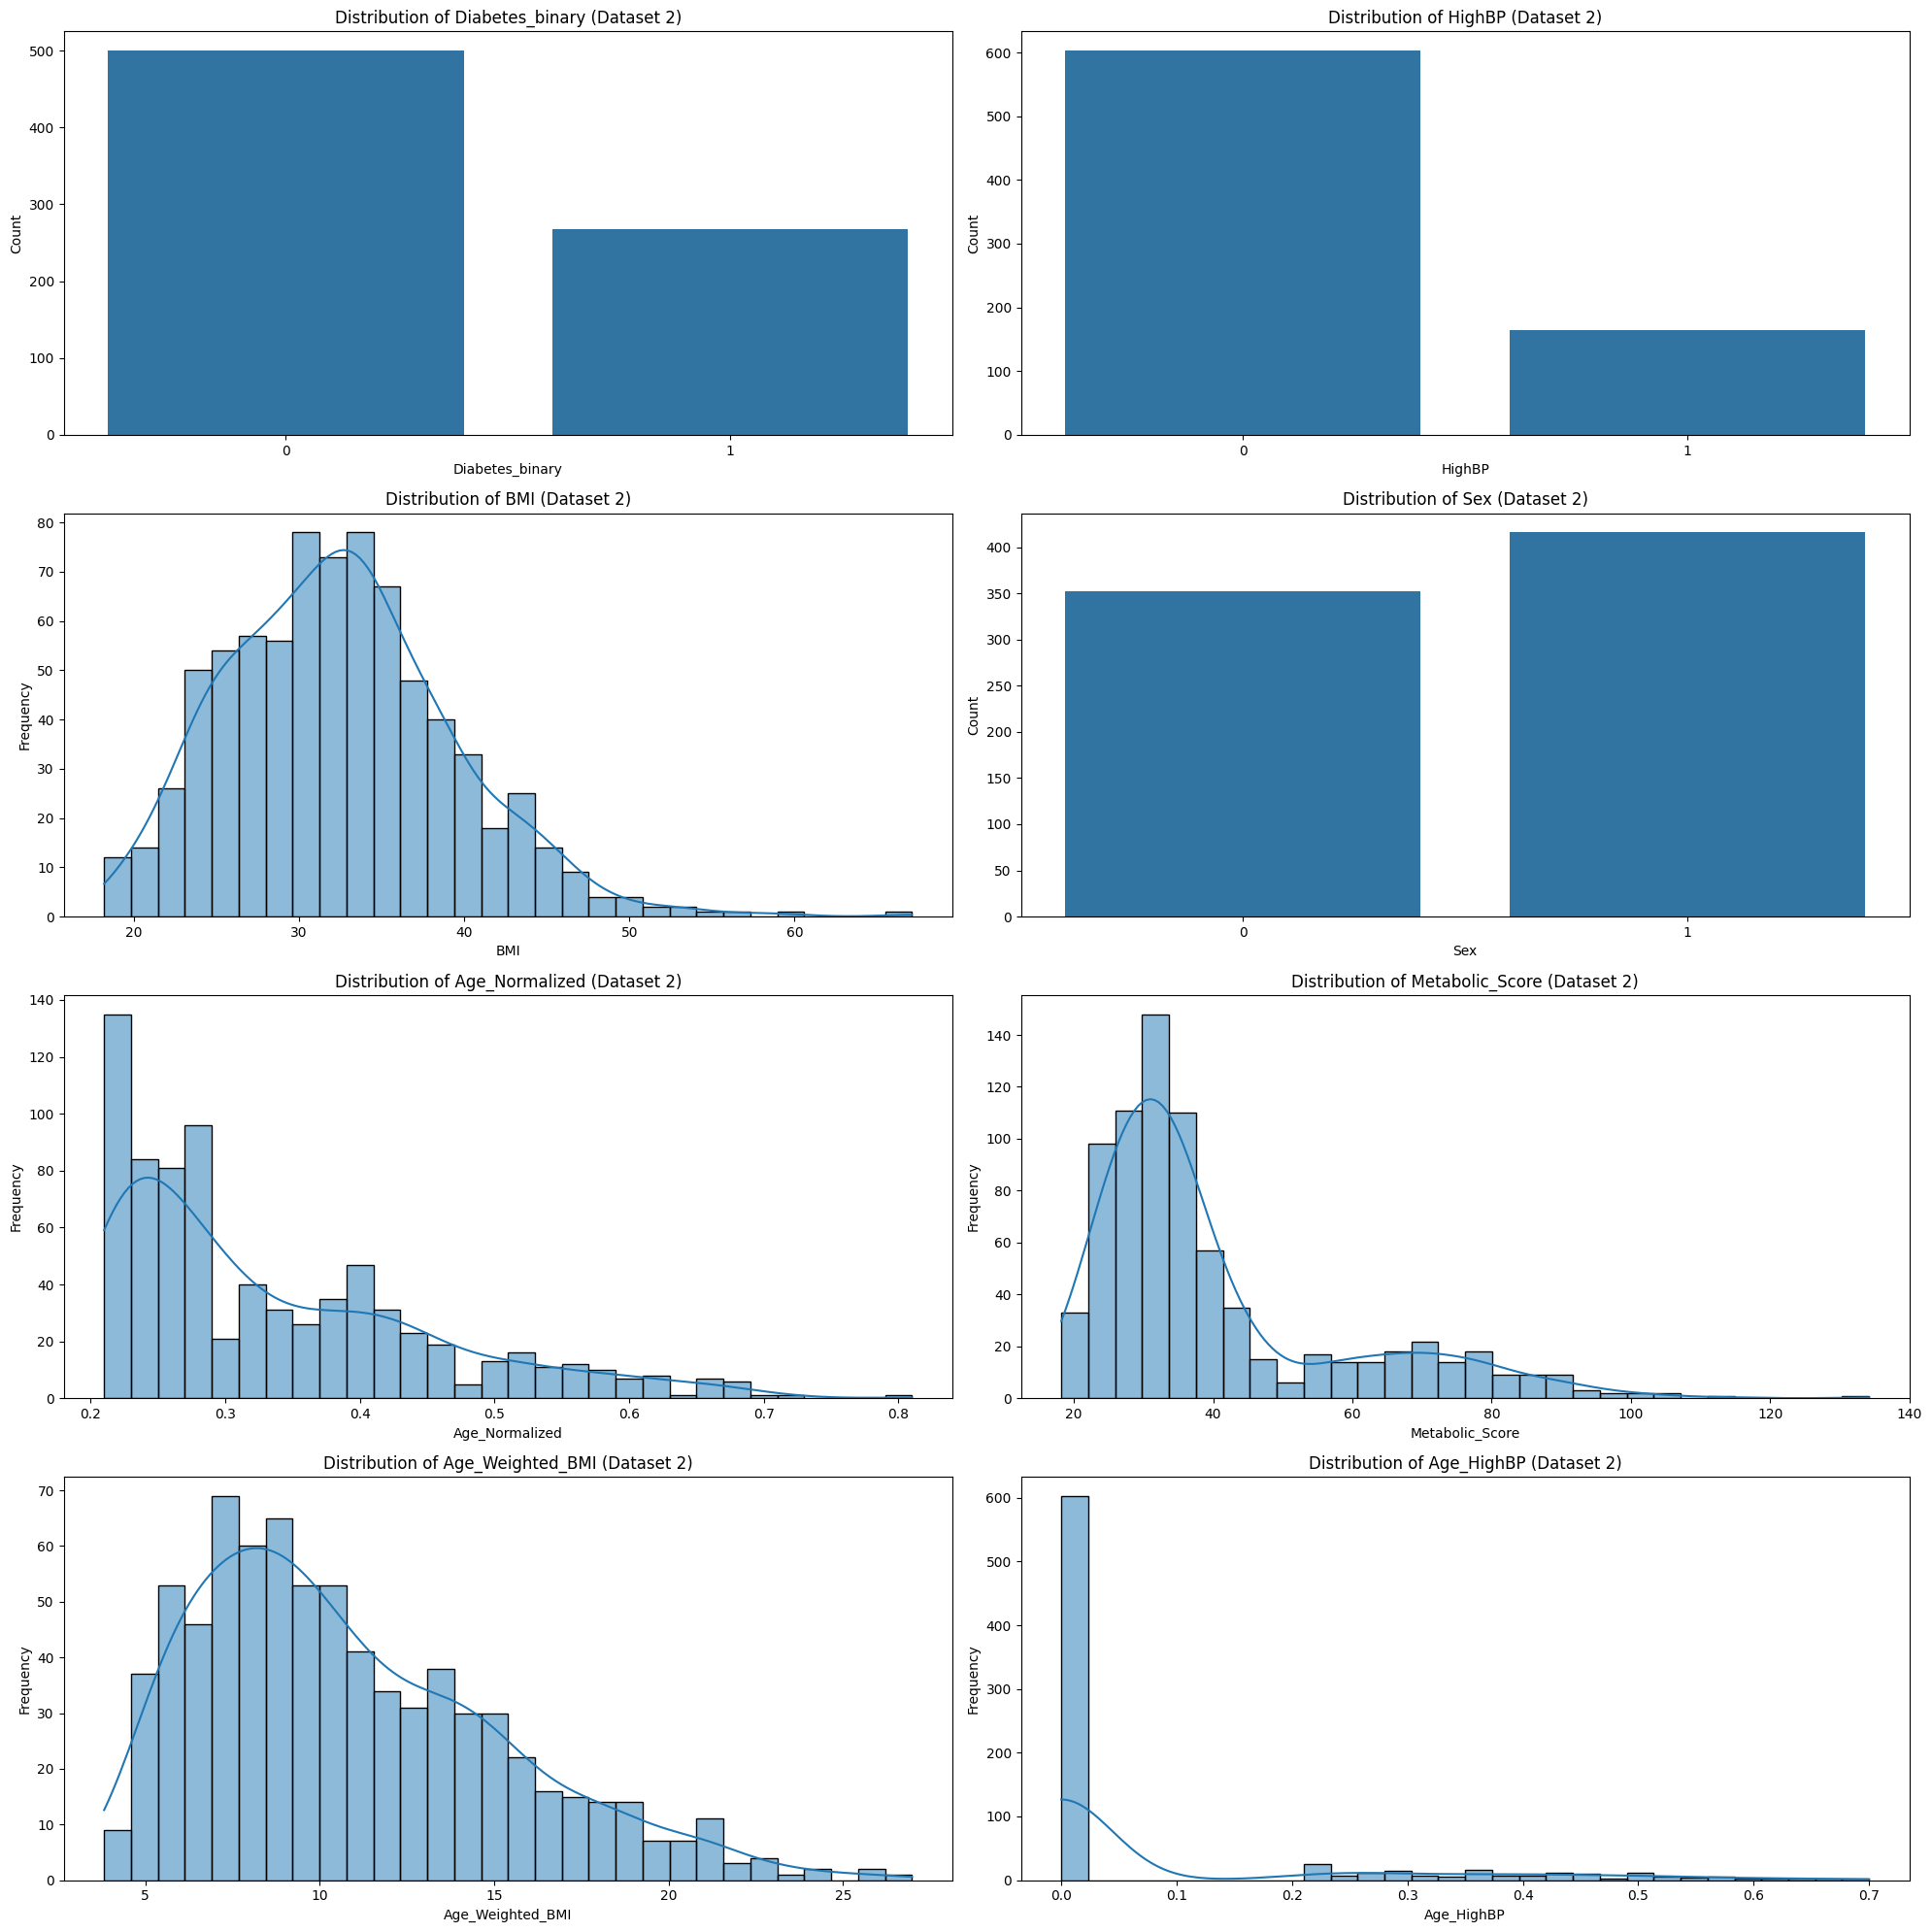

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(20, 20))
axes = axes.flatten() # Flatten the 4x2 array of axes for easy iteration

features_to_visualize = [
    'Diabetes_binary', 'HighBP', 'BMI', 'Sex', 'Age_Normalized',
    'Metabolic_Score', 'Age_Weighted_BMI', 'Age_HighBP'
]

for i, feature in enumerate(features_to_visualize):
    ax = axes[i]
    if feature in ['Diabetes_binary', 'HighBP', 'Sex']:
        sns.countplot(x=feature, data=df2_final, ax=ax)
        ax.set_ylabel('Count')
    else:
        sns.histplot(df2_final[feature], bins=30, kde=True, ax=ax)
        ax.set_ylabel('Frequency')

    ax.set_title(f'Distribution of {feature} (Dataset 2)')
    ax.set_xlabel(feature)

plt.tight_layout()
plt.show()

# Hyperparameter Tuning

In [ ]:
# Hyperparameter Tuning
# We will tune distinct models. For brevity, we define a helper function.

def tune_model(model, param_dist, X_train, y_train):
    random_search = RandomizedSearchCV(model, param_distributions=param_dist, n_iter=5, cv=3, scoring='f1', n_jobs=-1, random_state=42)
    random_search.fit(X_train, y_train)
    return random_search.best_estimator_, random_search.best_params_

print("Hyperparameter tuning setup ready.")

Hyperparameter tuning setup ready.


## 10.1 Supervised Data Mining Algorithms (Classification)
Training on Dataset 1, Testing on Small Dataset.

Starting Model Training & Evaluation...
Creating subsample of 15000 for computationally expensive models (SVM, ANN, kNN)...
Training Decision Tree...
  Best Params: {'max_depth': 10, 'min_samples_split': 2}
  Accuracy: 0.6784, F1: 0.3551


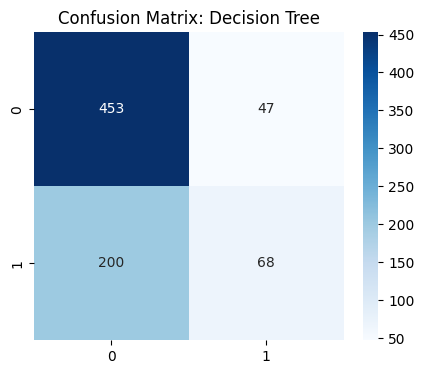

Training Random Forest...
  Best Params: {'max_depth': 10, 'n_estimators': 100}
  Accuracy: 0.6797, F1: 0.3692


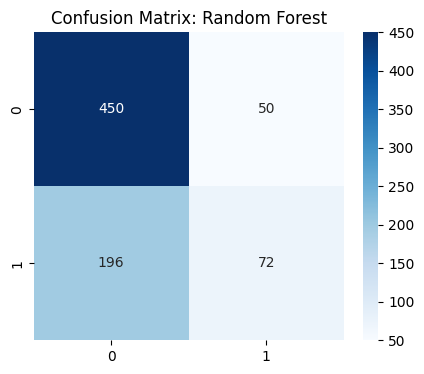

Training XGBoost...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [01:04:22] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


  Best Params: {'learning_rate': 0.01, 'n_estimators': 50}
  Accuracy: 0.6823, F1: 0.3613


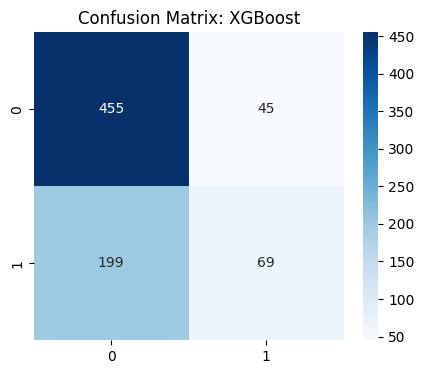

Training Logistic Regression...
  Best Params: {'C': 1.0}
  Accuracy: 0.6680, F1: 0.3577


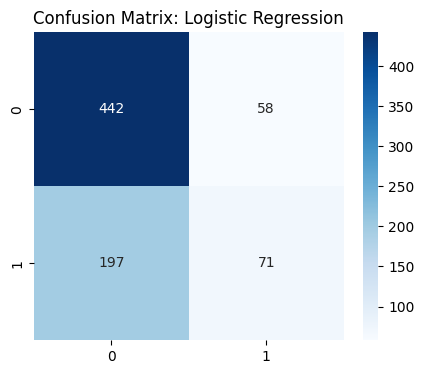

Training kNN...
  Using subsampled data (15000 samples)
  Best Params: {'n_neighbors': 7}
  Accuracy: 0.6862, F1: 0.3773


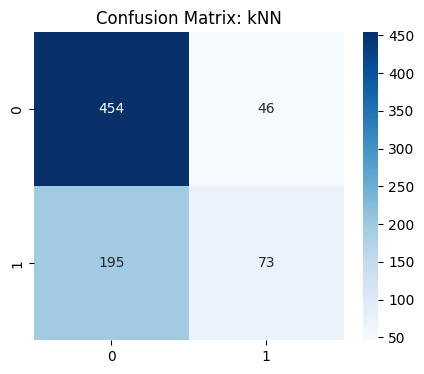

Training SVM...
  Using subsampled data (15000 samples)


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


  Best Params: {'C': 1, 'gamma': 'scale'}
  Accuracy: 0.6732, F1: 0.3514


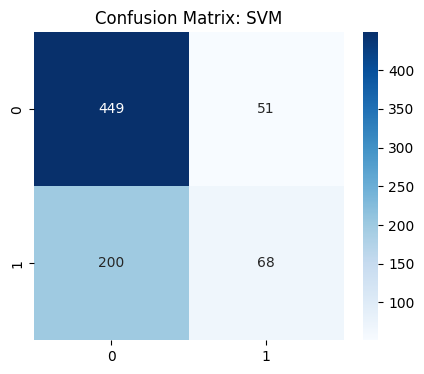

Training GaussianNB...
  Accuracy: 0.6758, F1: 0.3324


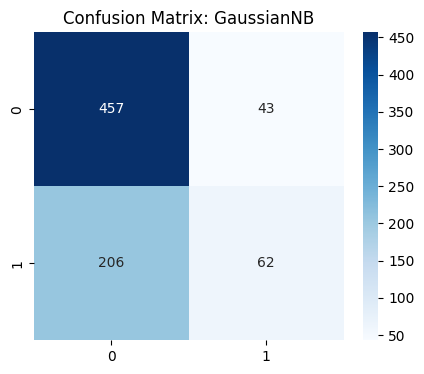

Training ANN (MLP)...
  Using subsampled data (15000 samples)
  Best Params: {'alpha': 0.0001, 'hidden_layer_sizes': (50,)}
  Accuracy: 0.6719, F1: 0.3636


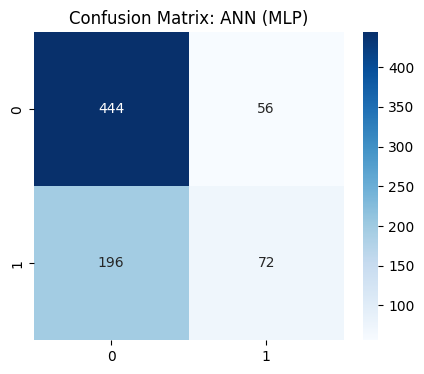

,Algorithm,Accuracy,F1 Score
0,Decision Tree,0.678385,0.355091
1,Random Forest,0.679688,0.369231
2,XGBoost,0.682292,0.361257
3,Logistic Regression,0.667969,0.357683
4,kNN,0.686198,0.377261
5,SVM,0.673177,0.351421
6,GaussianNB,0.675781,0.332440
7,ANN (MLP),0.671875,0.363636


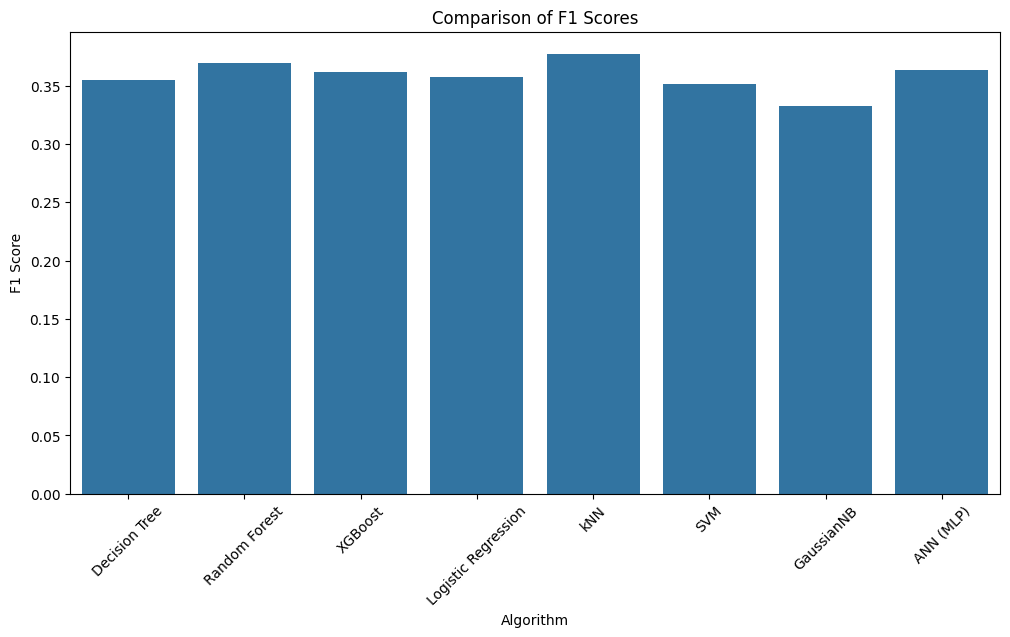

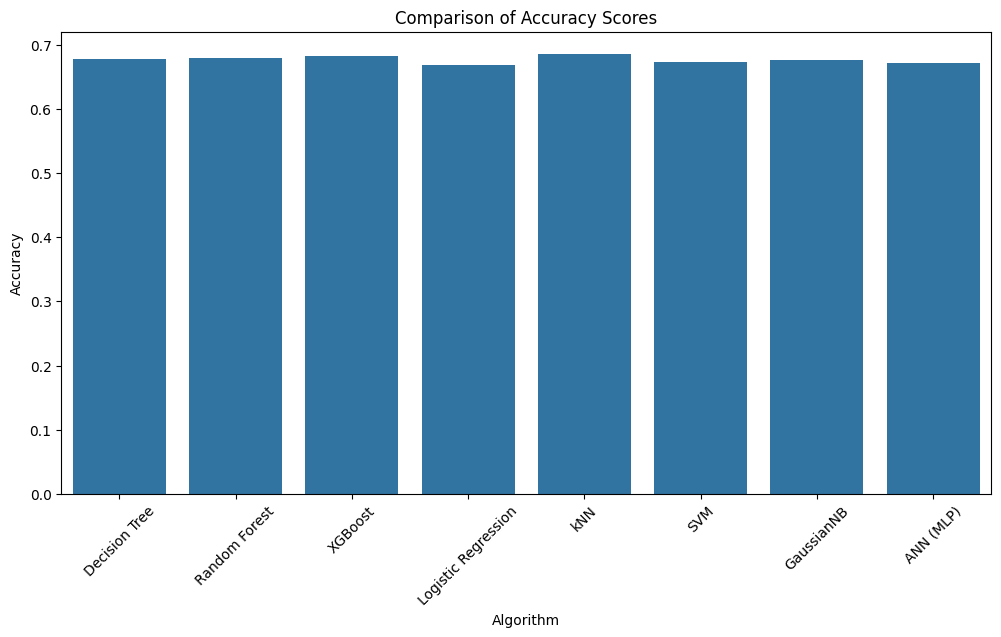

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import time

def tune_model(model, param_grid, X, y):
    grid_search = GridSearchCV(model, param_grid, cv=3, scoring='f1', n_jobs=-1, verbose=0)
    grid_search.fit(X, y)
    return grid_search.best_estimator_, grid_search.best_params_

# Prepare Data
X_train = df1_final.drop('Diabetes_binary', axis=1)
y_train = df1_final['Diabetes_binary']
X_test = df2_final.drop('Diabetes_binary', axis=1)
y_test = df2_final['Diabetes_binary']

# Scale features (important for KNN, SVM, ANN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

results = []

models = {
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "XGBoost": XGBClassifier(eval_metric='logloss', use_label_encoder=False),
    "Logistic Regression": LogisticRegression(solver='liblinear'),
    "kNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, kernel='rbf', cache_size=1000),
    "GaussianNB": GaussianNB(),
    "ANN (MLP)": MLPClassifier(max_iter=200, early_stopping=True, n_iter_no_change=10)
}

# Define simple param grids for limited tuning
param_grids = {
    "Decision Tree": {'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]},
    "Random Forest": {'n_estimators': [50, 100], 'max_depth': [None, 10]},
    "XGBoost": {'n_estimators': [50, 100], 'learning_rate': [0.01, 0.1]},
    "Logistic Regression": {'C': [0.1, 1.0]},
    "kNN": {'n_neighbors': [3, 5, 7]},
    "SVM": {'C': [0.1, 1], 'gamma': ['scale']},
    "GaussianNB": {},
    "ANN (MLP)": {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.0001]}
}

print("Starting Model Training & Evaluation...")

# Dictionary to save trained models for export
trained_models = {}

MAX_SAMPLES = 15000
if len(X_train_scaled) > MAX_SAMPLES:
    print(f"Creating subsample of {MAX_SAMPLES} for computationally expensive models (SVM, ANN, kNN)...")
    # Stratified sample
    # Note: For stratification, y_train needs to be integers or object types for `choice` to work if it's based on values.
    # Assuming y_train is binary (0 or 1), direct sampling is okay if not stratified explicitly.
    indices = np.random.choice(len(X_train_scaled), MAX_SAMPLES, replace=False)
    X_train_sub = X_train_scaled[indices]
    y_train_sub = y_train.iloc[indices]
else:
    X_train_sub = X_train_scaled
    y_train_sub = y_train

for name, model in models.items():
    start_time = time.time()
    print(f"Training {name}...")

    # Select correctly scaled/sampled data
    if name in ["kNN", "SVM", "ANN (MLP)"]:
        # Use subsampled scaled data
        X_tr, y_tr = X_train_sub, y_train_sub
        X_te = X_test_scaled
        print(f"  Using subsampled data ({len(X_tr)} samples)")
    elif name == "Logistic Regression": # LogReg also benefits from scaled data
        X_tr, y_tr = X_train_scaled, y_train
        X_te = X_test_scaled
    elif name == "GaussianNB": # GaussianNB also benefits from scaled data
        X_tr, y_tr = X_train_scaled, y_train
        X_te = X_test_scaled
    else:
        # Tree models handle large data better, use full unscaled (or scaled doesn't matter much)
        # Note: XGBoost with eval_metric='logloss' and use_label_encoder=False also avoids warnings
        X_tr, y_tr = X_train, y_train
        X_te = X_test

    # Hyperparameter Tuning
    if name in param_grids and param_grids[name]:
        best_model, best_params = tune_model(model, param_grids[name], X_tr, y_tr)
        print(f"  Best Params: {best_params}")
    else:
        best_model = model
        best_model.fit(X_tr, y_tr)

    # Prediction
    y_pred = best_model.predict(X_te)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Algorithm": name,
        "Accuracy": acc,
        "F1 Score": f1
    })

    trained_models[name] = best_model

    print(f"  Accuracy: {acc:.4f}, F1: {f1:.4f}")

    # Visualization
    conf_matrix = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix: {name}')
    plt.show()

# Comparison Visualization
results_df = pd.DataFrame(results)
display(results_df)

plt.figure(figsize=(12, 6))
sns.barplot(x='Algorithm', y='F1 Score', data=results_df)
plt.title('Comparison of F1 Scores')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x='Algorithm', y='Accuracy', data=results_df)
plt.title('Comparison of Accuracy Scores')
plt.xticks(rotation=45)
plt.show()


## 11. Explainable AI (XAI)
In this section, we use **SHAP (SHapley Additive exPlanations)** and **Feature Importance** to understand how our best-performing models make decisions. This is crucial for healthcare applications to ensure transparency and trust.

/tmp/ipython-input-591045317.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')


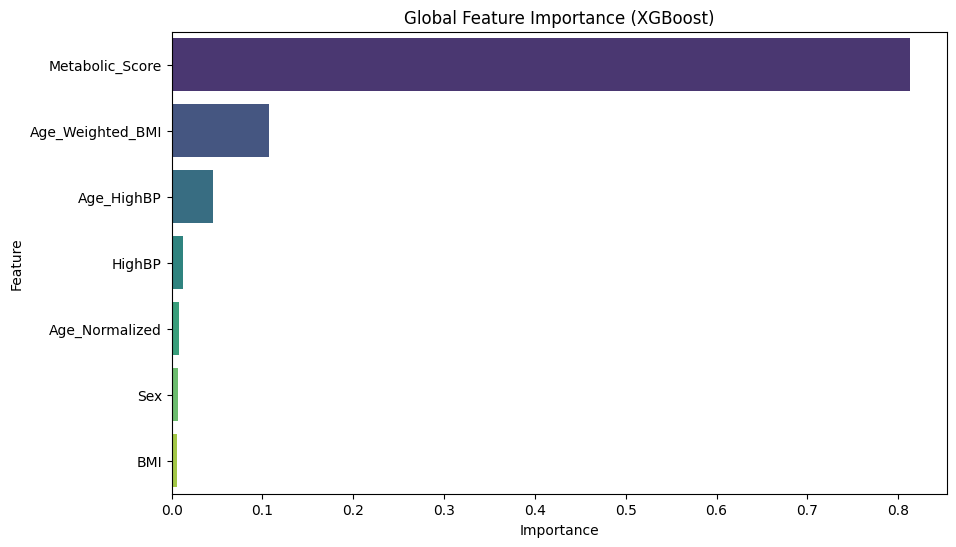

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Global Interpretability: XGBoost Feature Importance
if 'trained_models' in globals() and 'XGBoost' in trained_models:
    model_xgb = trained_models['XGBoost']
    importances = model_xgb.feature_importances_

    # Check if X_train exists from the preparation step
    if 'X_train' in globals():
        feature_names = X_train.columns

        # Create a DataFrame for visualization
        feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
        feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

        plt.figure(figsize=(10, 6))
        sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')
        plt.title('Global Feature Importance (XGBoost)')
        plt.show()
    else:
        print("X_train not found. Please ensure the data preparation and scaling steps have been executed.")
else:
    print("XGBoost model not found in 'trained_models'. Please run the classification training cell (FS2Ipkjke8Uv) first.")

## 10.2 Clustering Data Mining Algorithms
Evaluate Silhouette Score and Visualize Clusters using PCA (2D projection).

Running k-Means...


/tmp/ipython-input-1670809377.py:61: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color = cm.get_cmap('nipy_spectral')(float(i) / n_clusters)


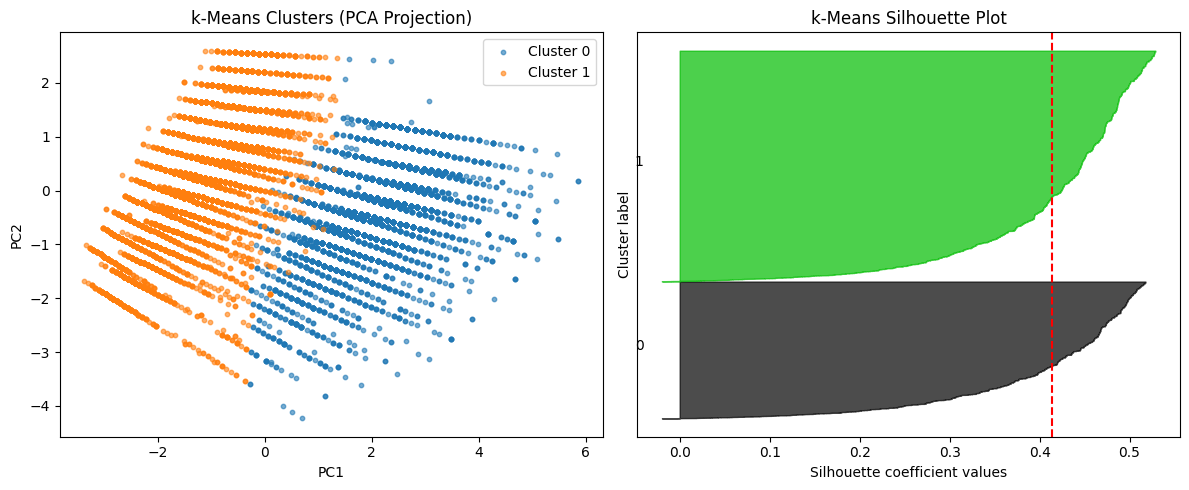

  Silhouette Score: 0.4144
Running DBSCAN...


/tmp/ipython-input-1670809377.py:61: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color = cm.get_cmap('nipy_spectral')(float(i) / n_clusters)


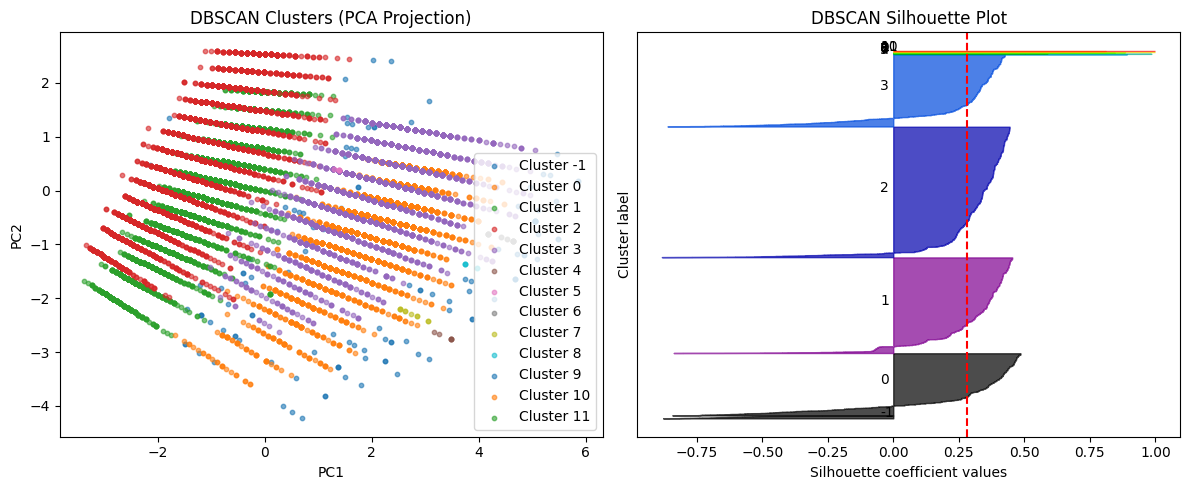

  Silhouette Score: 0.2829
Running Hierarchical...


/tmp/ipython-input-1670809377.py:61: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color = cm.get_cmap('nipy_spectral')(float(i) / n_clusters)


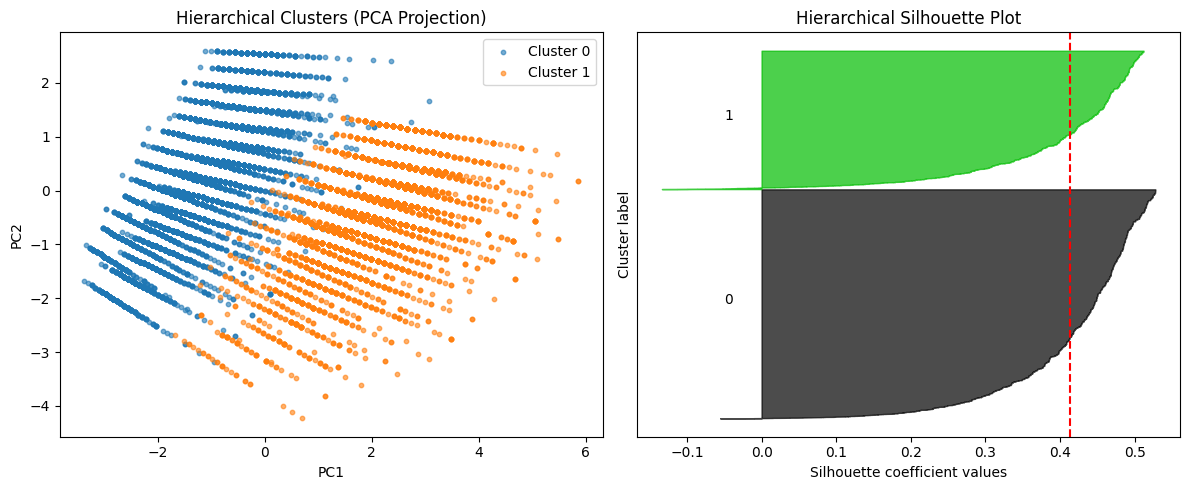

  Silhouette Score: 0.4136


,Algorithm,Silhouette Score
0,k-Means,0.414361
1,DBSCAN,0.282855
2,Hierarchical,0.413610


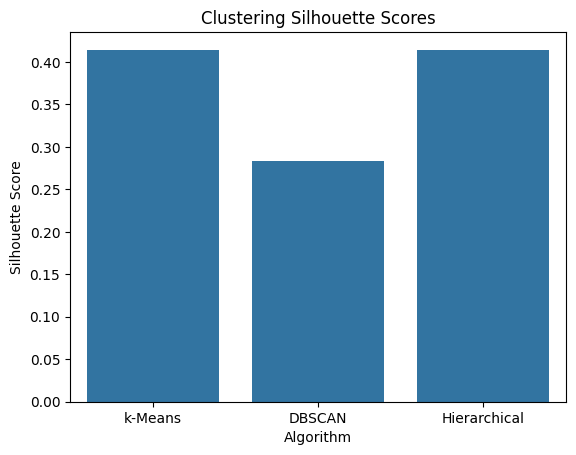

In [ ]:
from sklearn.decomposition import PCA # Import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
import matplotlib.cm as cm # Import colormap for silhouette plot
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Clustering
X_cluster = X_train_scaled[:15000] # Use 15000 samples for speed

# Reduce dimensions for visualization (2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster)

clustering_models = {
    "k-Means": KMeans(n_clusters=2, random_state=42, n_init=10), # Added n_init to avoid future warning
    "DBSCAN": DBSCAN(eps=0.5, min_samples=5),
    "Hierarchical": AgglomerativeClustering(n_clusters=2)
}

cluster_results = []

for name, model in clustering_models.items():
    print(f"Running {name}...")

    # Fit & Predict
    labels = model.fit_predict(X_cluster)

    # Silhouette Score
    unique_labels = np.unique(labels)
    n_clusters = len(unique_labels)

    if n_clusters > 1:
        score = silhouette_score(X_cluster, labels)

        # --- Visualization 1: Cluster Scatter Plot (PCA) ---
        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        for i in unique_labels:
            plt.scatter(X_pca[labels == i, 0], X_pca[labels == i, 1], label=f'Cluster {i}', alpha=0.6, s=10)
        plt.title(f'{name} Clusters (PCA Projection)')
        plt.xlabel('PC1')
        plt.ylabel('PC2')
        plt.legend()

        # --- Visualization 2: Silhouette Plot ---
        plt.subplot(1, 2, 2)
        sample_silhouette_values = silhouette_samples(X_cluster, labels)
        y_lower = 10

        for i in unique_labels:
            ith_cluster_silhouette_values = sample_silhouette_values[labels == i]
            ith_cluster_silhouette_values.sort()

            size_cluster_i = ith_cluster_silhouette_values.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.get_cmap('nipy_spectral')(float(i) / n_clusters)
            plt.fill_betweenx(np.arange(y_lower, y_upper),
                              0, ith_cluster_silhouette_values,
                              facecolor=color, edgecolor=color, alpha=0.7)

            # Label the silhouette plots with their cluster numbers at the middle
            plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
            y_lower = y_upper + 10  # 10 for the 0 samples

        plt.title(f'{name} Silhouette Plot')
        plt.xlabel("Silhouette coefficient values")
        plt.ylabel("Cluster label")
        plt.axvline(x=score, color="red", linestyle="--") # Vertical line for average silhouette score
        plt.yticks([])  # Clear the yaxis labels / ticks

        plt.tight_layout()
        plt.show()

    else:
        score = -1 # Error code/Noise only
        print(f"  {name} found only 1 cluster/noise. Skipping plots.")

    cluster_results.append({"Algorithm": name, "Silhouette Score": score})
    print(f"  Silhouette Score: {score:.4f}")

# Comparison Visualization
cluster_df = pd.DataFrame(cluster_results)
display(cluster_df)
plt.figure()
sns.barplot(x='Algorithm', y='Silhouette Score', data=cluster_df)
plt.title('Clustering Silhouette Scores')
plt.show()

## 10.2.1 Clustering Interpretability (XAI for Clustering)
To explain our clusters, we analyze the 'Centroids' (average feature values). This allows us to understand the clinical characteristics that define each group.

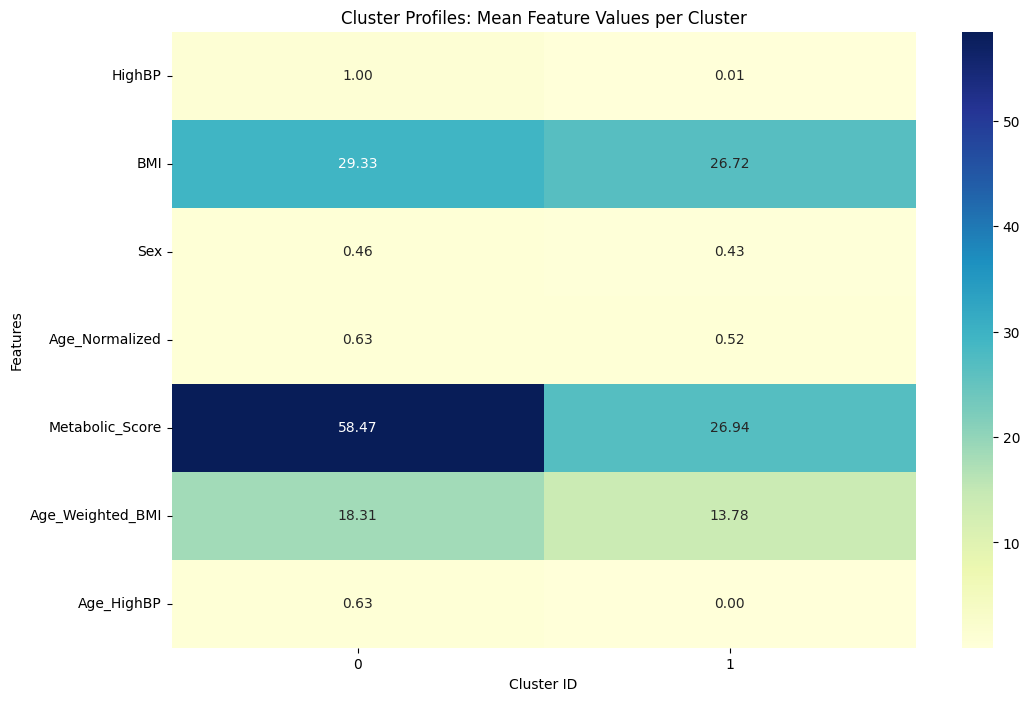

Interpretation Note: Look for features with the largest differences between clusters.
For example, if Cluster 1 has a significantly higher mean 'BMI' than Cluster 0, it represents a higher-risk group.


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# --- 1. Check for required data and models ---
if 'clustering_models' not in globals():
    from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
    clustering_models = {
        "k-Means": KMeans(n_clusters=2, random_state=42, n_init=10),
        "DBSCAN": DBSCAN(eps=0.5, min_samples=5),
        "Hierarchical": AgglomerativeClustering(n_clusters=2)
    }

if 'X_cluster' not in globals():
    if 'X_train_scaled' in globals():
        X_cluster = X_train_scaled[:15000]
    else:
        print("Required data 'X_train_scaled' not found. Please run the model training cell (FS2Ipkjke8Uv) first.")
        X_cluster = None

if X_cluster is not None:
    # 1. Re-run k-Means to get stable labels for interpretation
    kmeans_model = clustering_models['k-Means']
    cluster_labels = kmeans_model.fit_predict(X_cluster)

    # 2. Map labels back to the original (unscaled) feature values for better readability
    if 'X_train' in globals():
        df_cluster_interpret = X_train.iloc[:len(X_cluster)].copy()
        df_cluster_interpret['Cluster'] = cluster_labels

        # 3. Calculate mean values for each cluster
        cluster_profiles = df_cluster_interpret.groupby('Cluster').mean()

        # 4. Visualize the differences using a Heatmap
        plt.figure(figsize=(12, 8))
        sns.heatmap(cluster_profiles.T, annot=True, cmap='YlGnBu', fmt='.2f')
        plt.title('Cluster Profiles: Mean Feature Values per Cluster')
        plt.ylabel('Features')
        plt.xlabel('Cluster ID')
        plt.show()

        print("Interpretation Note: Look for features with the largest differences between clusters.")
        print("For example, if Cluster 1 has a significantly higher mean 'BMI' than Cluster 0, it represents a higher-risk group.")
    else:
        print("X_train not found. Please ensure the data preparation steps have been executed.")

## 10.3 Association Rule Data Mining
Using Apriori and FP-Growth.

Running Apriori...
Running FP-Growth...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

,Algorithm,Avg Lift,Avg Confidence
0,Apriori,1.25624,0.484371
1,FP-Growth,1.25624,0.484371


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


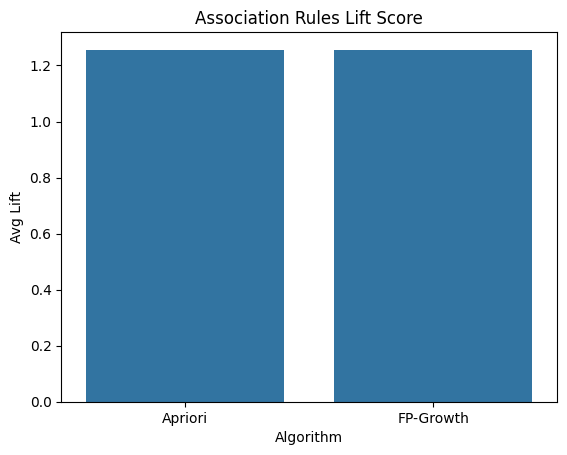

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
# Association Rules
# Need binary data (0/1). Dataset 1 is already mostly binary/categorical.
# We need to bin continuous variables (BMI, Age) for Association Rules
df_assoc = df1_final.copy()
# Bin BMI
df_assoc['BMI_Bin'] = pd.cut(df_assoc['BMI'], bins=[0, 18.5, 25, 30, 100], labels=['Underweight', 'Normal', 'Overweight', 'Obese'])
# Bin Age
df_assoc['Age_Bin'] = pd.cut(df_assoc['Age_Normalized'], bins=3, labels=['Young', 'Middle', 'Old'])

# One-hot encode
df_assoc_encoded = pd.get_dummies(df_assoc[['HighBP', 'Diabetes_binary', 'Sex', 'BMI_Bin', 'Age_Bin']], columns=['BMI_Bin', 'Age_Bin'])
# Convert to bool
df_assoc_bool = df_assoc_encoded.astype(bool)

assoc_results = []

# Apriori
print("Running Apriori...")
from mlxtend.frequent_patterns import apriori, association_rules
frequent_itemsets_ap = apriori(df_assoc_bool, min_support=0.1, use_colnames=True)
rules_ap = association_rules(frequent_itemsets_ap, metric="lift", min_threshold=1.0)
if not rules_ap.empty:
    avg_lift_ap = rules_ap['lift'].mean()
    avg_conf_ap = rules_ap['confidence'].mean()
else:
    avg_lift_ap = 0
    avg_conf_ap = 0

assoc_results.append({"Algorithm": "Apriori", "Avg Lift": avg_lift_ap, "Avg Confidence": avg_conf_ap})

# FP-Growth
print("Running FP-Growth...")
# mlxtend fpgrowth implementation
from mlxtend.frequent_patterns import fpgrowth
frequent_itemsets_fp = fpgrowth(df_assoc_bool, min_support=0.1, use_colnames=True)
rules_fp = association_rules(frequent_itemsets_fp, metric="lift", min_threshold=1.0)
if not rules_fp.empty:
    avg_lift_fp = rules_fp['lift'].mean()
    avg_conf_fp = rules_fp['confidence'].mean()
else:
    avg_lift_fp = 0
    avg_conf_fp = 0

assoc_results.append({"Algorithm": "FP-Growth", "Avg Lift": avg_lift_fp, "Avg Confidence": avg_conf_fp})

# Visualization
assoc_df = pd.DataFrame(assoc_results)
display(assoc_df)

plt.figure()
sns.barplot(x='Algorithm', y='Avg Lift', data=assoc_df)
plt.title('Association Rules Lift Score')
plt.show()

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Starting Association Rule Mining with Support Tuning...

Tuning Apriori...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


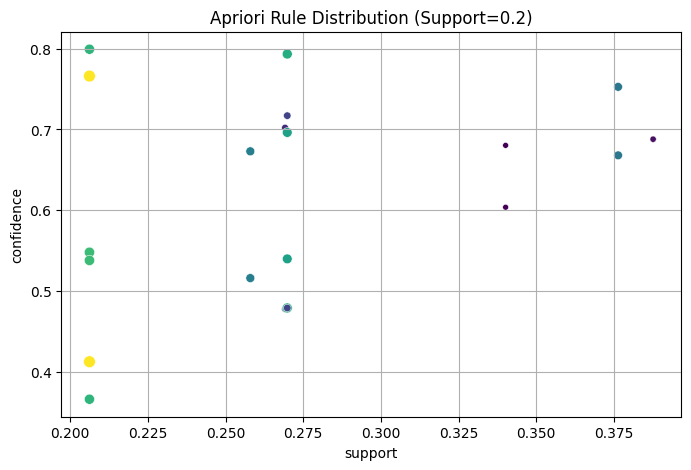

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


>>> Apriori Analysis Complete (Rules: 22).

Tuning FP-Growth...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

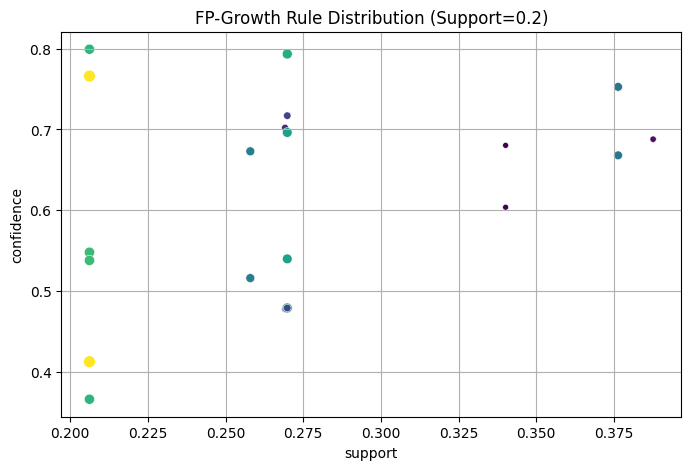

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

>>> FP-Growth Analysis Complete (Rules: 22).


ASSOCIATION RULES PERFORMANCE SUMMARY
   Algorithm  Avg Lift  Avg Confidence  Rules Found  Best Support
0    Apriori  1.346222        0.617371           22           0.2
1  FP-Growth  1.346222        0.617371           22           0.2

--- XAI: Top Feature Associations ---


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

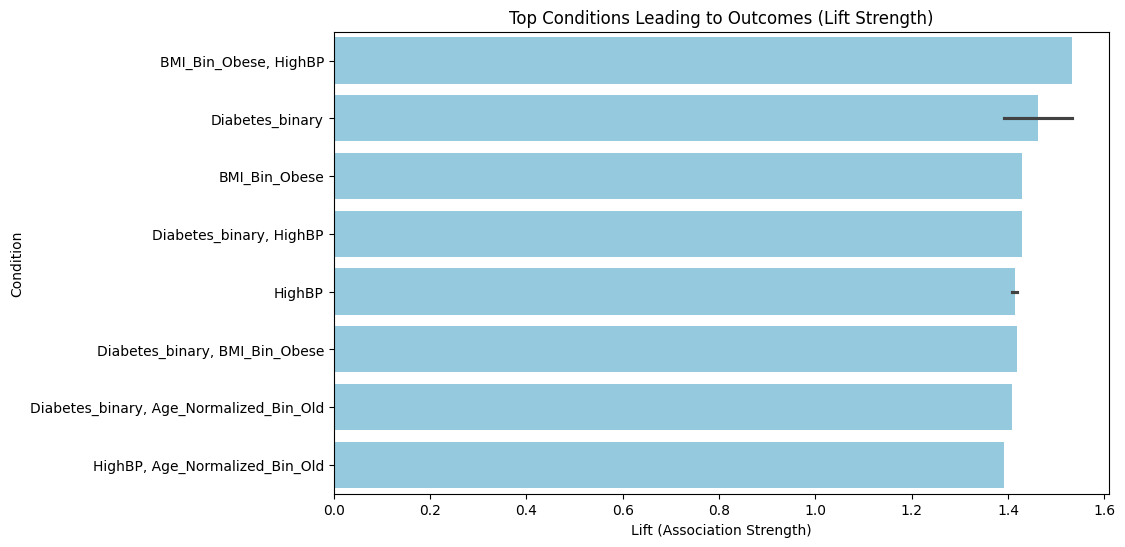

>>> XAI Insight: Higher lift = stronger association between condition and outcome.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

# --- 1. Check for Data ---
if 'df1_final' not in globals():
    raise ValueError("df1_final not found. Run preprocessing first.")

print("Starting Association Rule Mining with Support Tuning...\n")

# --- 2. Prepare Data ---
df_assoc = df1_final.copy()

# Safe BMI binning
df_assoc['BMI_Bin'] = pd.cut(
    df_assoc['BMI'],
    bins=[0, 18.5, 25, 30, 100],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
)

# Safe Age handling
if 'Age_Normalized' not in df_assoc.columns:
    df_assoc['Age_Normalized'] = (df_assoc['Age'] - df_assoc['Age'].min()) / (df_assoc['Age'].max() - df_assoc['Age'].min())

df_assoc['Age_Normalized_Bin'] = pd.cut(df_assoc['Age_Normalized'], bins=3, labels=['Young', 'Middle', 'Old'])

# One-hot encoding
df_assoc_encoded = pd.get_dummies(
    df_assoc[['HighBP', 'Diabetes_binary', 'Sex', 'BMI_Bin', 'Age_Normalized_Bin']],
    columns=['BMI_Bin', 'Age_Normalized_Bin']
).astype(bool)

# --- 3. Mining Logic ---
support_levels = [0.2, 0.1, 0.05, 0.03]
assoc_results = []
best_rules_dict = {}

for algo_name in ["Apriori", "FP-Growth"]:
    print(f"Tuning {algo_name}...")
    final_rules = pd.DataFrame()
    chosen_support = None

    for sup in support_levels:
        if algo_name == "Apriori":
            frequent_itemsets = apriori(df_assoc_encoded, min_support=sup, use_colnames=True)
        else:
            frequent_itemsets = fpgrowth(df_assoc_encoded, min_support=sup, use_colnames=True)

        if frequent_itemsets.empty:
            continue

        rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.2)

        if len(rules) >= 5:
            final_rules = rules
            chosen_support = sup
            break

    if not final_rules.empty:
        avg_lift = final_rules['lift'].mean()
        avg_conf = final_rules['confidence'].mean()
        best_rules_dict[algo_name] = final_rules
    else:
        avg_lift, avg_conf = 0, 0

    assoc_results.append({
        "Algorithm": algo_name,
        "Avg Lift": avg_lift,
        "Avg Confidence": avg_conf,
        "Rules Found": len(final_rules),
        "Best Support": chosen_support
    })

    # --- Visualization ---
    if not final_rules.empty:
        plt.figure(figsize=(8, 5))
        sns.scatterplot(
            x="support",
            y="confidence",
            size="lift",
            hue="lift",
            data=final_rules,
            palette="viridis",
            legend=False
        )
        plt.title(f"{algo_name} Rule Distribution (Support={chosen_support})")
        plt.grid(True)
        plt.show()

        print(f">>> {algo_name} Analysis Complete (Rules: {len(final_rules)}).\n")
    else:
        print(f"No valid rules found for {algo_name}.\n")

# --- 4. Summary ---
assoc_df = pd.DataFrame(assoc_results)
print("\nASSOCIATION RULES PERFORMANCE SUMMARY")
print(assoc_df)

# --- 5. XAI Visualization (FIXED) ---
if "FP-Growth" in best_rules_dict and not best_rules_dict["FP-Growth"].empty:
    print("\n--- XAI: Top Feature Associations ---")
    top_rules = best_rules_dict["FP-Growth"].sort_values(by='lift', ascending=False).head(10)

    # Convert sets to readable labels
    top_rules['Antecedent'] = top_rules['antecedents'].apply(lambda x: ', '.join(list(x)))
    top_rules['Consequent'] = top_rules['consequents'].apply(lambda x: ', '.join(list(x)))

    plt.figure(figsize=(10, 6))
    sns.barplot(x='lift', y='Antecedent', data=top_rules, color='skyblue')
    plt.title("Top Conditions Leading to Outcomes (Lift Strength)")
    plt.xlabel("Lift (Association Strength)")
    plt.ylabel("Condition")
    plt.show()

    print(">>> XAI Insight: Higher lift = stronger association between condition and outcome.")
else:
    print("\nNo FP-Growth rules available for XAI visualization.")


# TEST

In [ ]:
import pandas as pd
from IPython.display import display

# Referencing the data from the supervised learning assignment
if 'df1_cleaned' in globals():
    # Select 3 features and the target variable
    features = ['BMI', 'HighBP', 'Age_Raw']
    target = 'Diabetes_binary'

    # Prepare the subset
    df_subset = df1_cleaned[[target] + features]

    # 1. Randomly extract 20 records for training data
    train_data = df_subset.sample(n=20, random_state=42)

    # 2. Extract another 3 records at random for test data (avoiding overlap)
    remaining_data = df_subset.drop(train_data.index)
    test_data = remaining_data.sample(n=3, random_state=123)

    print("### Training Data (20 Records) ###")
    display(train_data)

    print("\n### Test Data (3 Records) ###")
    display(test_data)
else:
    print("Error: 'df1_cleaned' not found. Please execute the cleaning cells in section 10.1 first.")

### Training Data (20 Records) ###


,Diabetes_binary,BMI,HighBP,Age_Raw
44967,1.0,23.0,0.0,67
20220,0.0,33.0,0.0,82
23944,0.0,27.0,1.0,57
2707,0.0,29.0,0.0,52
42356,1.0,47.0,1.0,47
25806,0.0,21.0,1.0,47
70201,1.0,28.0,1.0,72
57464,1.0,33.0,1.0,82
45140,1.0,35.0,1.0,67
501,0.0,18.0,0.0,67



### Test Data (3 Records) ###


,Diabetes_binary,BMI,HighBP,Age_Raw
11457,0.0,20.0,0.0,67
52850,1.0,32.0,1.0,62
21396,0.0,26.0,1.0,57
